In [ ]:
# ============================================================
# 1. Import Libraries & Load Data
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from scipy.stats import loguniform

import torch
import torch.nn as nn
from skorch import NeuralNetClassifier

df = pd.read_csv('Normalized CSV.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 3 columns & rows:")
display(df.head(3))

Dataset Shape: (5000, 21)

First 3 columns & rows:


,Female Age,Number of attempts,AMH,Medicines and treatments,Egg retrieval date,Oocyte Maturity MII,Oocyte Maturity MI,Oocyte Maturity others,Male Age,Sperm count,...,Sperm morphology,Number of fertilized eggs,Embryo Grade 1,Embryo Grade 2,Embryo Grade 3,Embryo Grade 4,Number of embryos,frezzing,?-HCG,Output (Output(failed implantation or successful implantation)
0,0.172414,0.272727,0.002483,0.010989,0.00274,0.096154,0.03125,0.015385,0.657895,0.001739,...,0.000000,0.142857,0.15625,0.00000,0.0,0.0,0.250,0.0,0.001765,0
1,0.241379,0.090909,0.010407,0.021978,0.00274,0.153846,0.03125,0.015385,0.631579,0.391304,...,0.333333,0.200000,0.21875,0.03125,0.0,0.0,0.375,0.0,0.205882,1
2,0.517241,0.090909,0.005138,0.000000,0.00274,0.115385,0.09375,0.015385,0.394737,0.434783,...,0.666667,0.142857,0.18750,0.00000,0.0,0.0,0.375,0.0,0.221029,1


In [ ]:
# ============================================================
# 2. Data Preparation, Feature Selection & Train-Test Split (Fixed)
# ============================================================

X = df.drop(columns=[df.columns[19], df.columns[-1]]).values.astype(np.float32)
y = df.iloc[:, -1].values.astype(np.int64)

print("Target distribution:")
print(pd.Series(y).value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTraining set shape: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Testing set shape:  X_test={X_test.shape}, y_test={y_test.shape}")

Target distribution:
0    2508
1    2492
Name: count, dtype: int64

Training set shape: X_train=(4000, 19), y_train=(4000,)
Testing set shape:  X_test=(1000, 19), y_test=(1000,)


In [ ]:
# ============================================================
# 3. Define Binary PyTorch Neural Network Architectures (Fixed)
# ============================================================

class BinaryLinearClassifier(nn.Module):
    def __init__(self, input_dim=X_train.shape[1]):
        super(BinaryLinearClassifier, self).__init__()
        self.linear = nn.Linear(input_dim, 1)
        
    def forward(self, x):
        return self.linear(x).squeeze(1)


class BinaryStandardMLP(nn.Module):
    def __init__(self, input_dim=X_train.shape[1], hidden_dim1=64, hidden_dim2=32, dropout_rate=0.3):
        super(BinaryStandardMLP, self).__init__()
        self.layer1 = nn.Linear(input_dim, hidden_dim1)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_rate)
        
        self.layer2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_rate)
        
        self.output = nn.Linear(hidden_dim2, 1)
        
    def forward(self, x):
        x = self.dropout1(self.relu1(self.layer1(x)))
        x = self.dropout2(self.relu2(self.layer2(x)))
        x = self.output(x)
        return x.squeeze(1)


class BinaryDeepMLP(nn.Module):
    def __init__(self, input_dim=X_train.shape[1], 
                 hidden_dim1=64, hidden_dim2=64, hidden_dim3=16, 
                 dropout_rate1=0.3, dropout_rate2=0.2):
        super(BinaryDeepMLP, self).__init__()
        self.layer1 = nn.Linear(input_dim, hidden_dim1)
        self.bn1 = nn.BatchNorm1d(hidden_dim1)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout_rate1)
        
        self.layer2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.bn2 = nn.BatchNorm1d(hidden_dim2)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout_rate2)
        
        self.layer3 = nn.Linear(hidden_dim2, hidden_dim3)
        self.relu3 = nn.ReLU()
        
        self.output = nn.Linear(hidden_dim3, 1)
        
    def forward(self, x):
        x = self.drop1(self.relu1(self.bn1(self.layer1(x))))
        x = self.drop2(self.relu2(self.bn2(self.layer2(x))))
        x = self.relu3(self.layer3(x))
        x = self.output(x)
        return x.squeeze(1)

print("Binary architectures updated with .squeeze(1) successfully!")

Binary architectures updated with .squeeze(1) successfully!


In [ ]:
# ============================================================
# 4. Pipeline Setup, Hyperparameter Spaces & Cross-Validation
# ============================================================
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

linear_skorch = NeuralNetClassifier(
    BinaryLinearClassifier,
    criterion=nn.BCEWithLogitsLoss,
    optimizer=torch.optim.Adam,
    train_split=None,
    verbose=0
)

mlp_skorch = NeuralNetClassifier(
    BinaryStandardMLP,
    criterion=nn.BCEWithLogitsLoss,
    optimizer=torch.optim.Adam,
    train_split=None,
    verbose=0
)

deep_mlp_skorch = NeuralNetClassifier(
    BinaryDeepMLP,
    criterion=nn.BCEWithLogitsLoss,
    optimizer=torch.optim.Adam,
    train_split=None,
    verbose=0
)

linear_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('net', linear_skorch)
])

mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('net', mlp_skorch)
])

deep_mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('net', deep_mlp_skorch)
])

params_linear = {
    'net__lr': loguniform(1e-4, 1e-1),
    'net__max_epochs': [20, 40, 60],
    'net__batch_size': [32, 64, 128],
    'net__optimizer__weight_decay': loguniform(1e-6, 1e-3)
}

params_mlp = {
    'net__lr': loguniform(1e-4, 1e-2),
    'net__max_epochs': [40, 80, 120],
    'net__batch_size': [32, 64, 128],
    'net__module__hidden_dim1': [32, 64, 128],
    'net__module__hidden_dim2': [16, 32, 64],
    'net__module__dropout_rate': [0.2, 0.3, 0.5],
    'net__optimizer__weight_decay': loguniform(1e-6, 1e-3)
}

params_deep_mlp = {
    'net__lr': loguniform(1e-4, 1e-2),
    'net__max_epochs': [60, 100, 150],
    'net__batch_size': [32, 64, 128],
    'net__module__hidden_dim1': [64, 128],
    'net__module__hidden_dim2': [32, 64],
    'net__module__hidden_dim3': [16, 32],
    'net__module__dropout_rate1': [0.2, 0.3],
    'net__module__dropout_rate2': [0.1, 0.2],
    'net__optimizer__weight_decay': loguniform(1e-6, 1e-3)
}

models = {
    "Binary Linear Model": (linear_pipeline, params_linear, 10),
    "Binary Standard MLP": (mlp_pipeline, params_mlp, 15),
    "Binary Deep Regularized MLP": (deep_mlp_pipeline, params_deep_mlp, 15)
}

print("Pipelines, hyperparameter spaces, and models dictionary configured successfully!")

Pipelines, hyperparameter spaces, and models dictionary configured successfully!


In [ ]:
# ============================================================
# 5. RandomizedSearchCV Execution & Binary Evaluation (Fixed)
# ============================================================
trained_models = {}
results = []
best_parameters = {}
cv_scores = {}

y_train_f = y_train.astype(np.float32)
y_test_f = y_test.astype(np.float32)

for name, (model_pipeline, param_distributions, n_iter) in models.items():
    print("\n" + "=" * 70)
    print(f"Training Binary PyTorch Model via skorch: {name}")
    print("=" * 70)

    search = RandomizedSearchCV(
        estimator=model_pipeline,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        random_state=42,
        verbose=1,
        return_train_score=False
    )

    search.fit(X_train, y_train_f)

    best_estimator = search.best_estimator_
    trained_models[name] = best_estimator
    best_parameters[name] = search.best_params_
    cv_scores[name] = search.best_score_

    y_proba = best_estimator.predict_proba(X_test)
    if y_proba.ndim > 1 and y_proba.shape[1] > 1:
        y_pred = (y_proba[:, 1] >= 0.5).astype(int)
    else:
        y_pred = (y_proba >= 0.5).astype(int)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "CV F1": search.best_score_,
        "Test Accuracy": accuracy,
        "Test Precision": precision,
        "Test Recall": recall,
        "Test F1": f1
    })

    print("\nBest Parameters:")
    print(search.best_params_)
    print(f"CV F1 Score       : {search.best_score_:.4f}")
    print(f"Test Accuracy     : {accuracy:.4f}")
    print(f"Test Precision    : {precision:.4f}")
    print(f"Test Recall       : {recall:.4f}")
    print(f"Test F1 Score     : {f1:.4f}")


Training Binary PyTorch Model via skorch: Binary Linear Model
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Best Parameters:
{'net__batch_size': 128, 'net__lr': np.float64(0.007164040428191013), 'net__max_epochs': 60, 'net__optimizer__weight_decay': np.float64(0.0008906204386161679)}
CV F1 Score       : 0.7608
Test Accuracy     : 0.7710
Test Precision    : 0.7785
Test Recall       : 0.7550
Test F1 Score     : 0.7666

Training Binary PyTorch Model via skorch: Binary Standard MLP
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Best Parameters:
{'net__batch_size': 128, 'net__lr': np.float64(0.00391819434714174), 'net__max_epochs': 120, 'net__module__dropout_rate': 0.5, 'net__module__hidden_dim1': 32, 'net__module__hidden_dim2': 16, 'net__optimizer__weight_decay': np.float64(2.9380279387035354e-06)}
CV F1 Score       : 0.8124
Test Accuracy     : 0.8010
Test Precision    : 0.7609
Test Recall       : 0.8755
Test F1 Score     : 0.8142

Training Binary PyTorch Mo

FINAL BINARY MODEL COMPARISON TABLE


,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Binary Standard MLP,0.812380,0.801,0.760908,0.875502,0.814192
1,Binary Deep Regularized MLP,0.803499,0.799,0.785029,0.821285,0.802748
2,Binary Linear Model,0.760796,0.771,0.778468,0.755020,0.766565


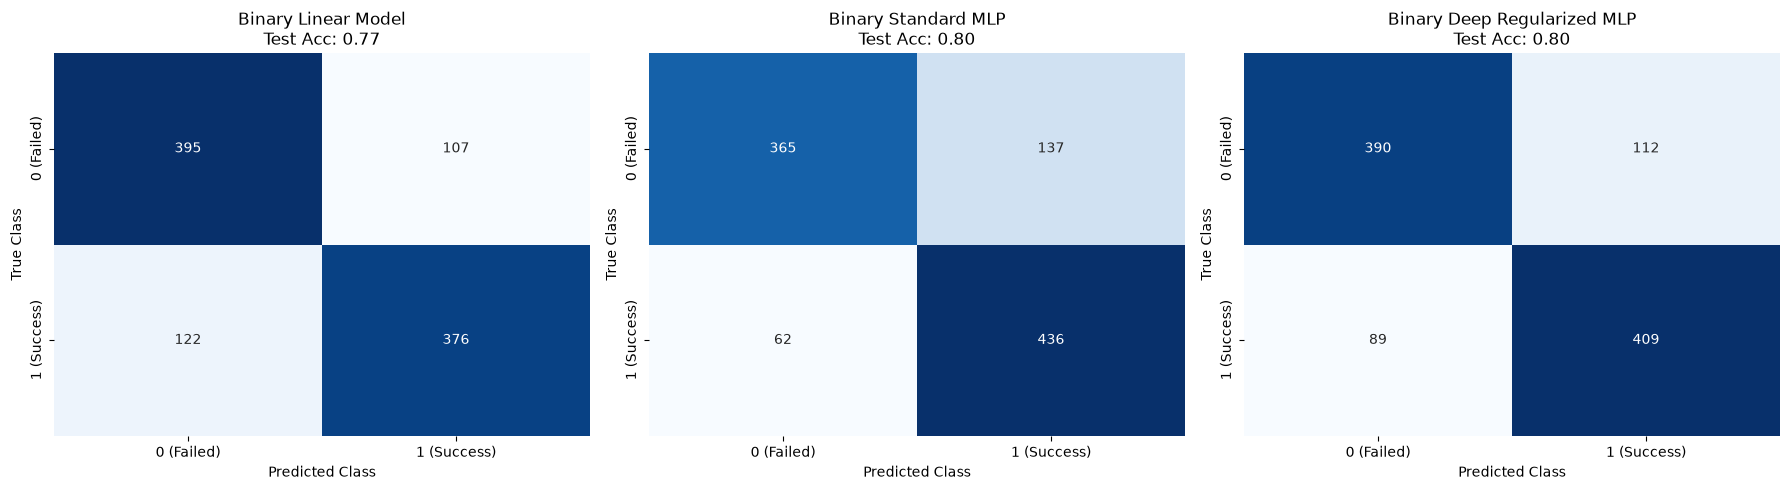

In [ ]:
# ============================================================
# 6. Summary Table & Binary Confusion Matrix Visualization
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

df_results = pd.DataFrame(results)
print("=" * 80)
print("FINAL BINARY MODEL COMPARISON TABLE")
print("=" * 80)
display(df_results.sort_values(by="Test F1", ascending=False).reset_index(drop=True))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
class_names = ["0 (Failed)", "1 (Success)"]

for idx, (name, model) in enumerate(trained_models.items()):
    y_proba = model.predict_proba(X_test)
    if y_proba.ndim > 1 and y_proba.shape[1] > 1:
        y_pred = (y_proba[:, 1] >= 0.5).astype(int)
    else:
        y_pred = (y_proba >= 0.5).astype(int)
        
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=class_names, yticklabels=class_names, cbar=False)
    axes[idx].set_title(f"{name}\nTest Acc: {accuracy_score(y_test, y_pred):.2f}")
    axes[idx].set_xlabel("Predicted Class")
    axes[idx].set_ylabel("True Class")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 7. Detailed Classification Report for Best Binary Model
# ============================================================
best_model_name = df_results.sort_values(by="Test F1", ascending=False).iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_proba_best = best_model.predict_proba(X_test)
if y_proba_best.ndim > 1 and y_proba_best.shape[1] > 1:
    y_pred_best = (y_proba_best[:, 1] >= 0.5).astype(int)
else:
    y_pred_best = (y_proba_best >= 0.5).astype(int)

print("=" * 80)
print(f"DETAILED BINARY CLASSIFICATION REPORT FOR BEST MODEL: {best_model_name}")
print("=" * 80)
binary_class_names = ["0 (Failed)", "1 (Success)"]
print(classification_report(y_test, y_pred_best, target_names=binary_class_names, zero_division=0))

DETAILED BINARY CLASSIFICATION REPORT FOR BEST MODEL: Binary Standard MLP
              precision    recall  f1-score   support

  0 (Failed)       0.85      0.73      0.79       502
 1 (Success)       0.76      0.88      0.81       498

    accuracy                           0.80      1000
   macro avg       0.81      0.80      0.80      1000
weighted avg       0.81      0.80      0.80      1000



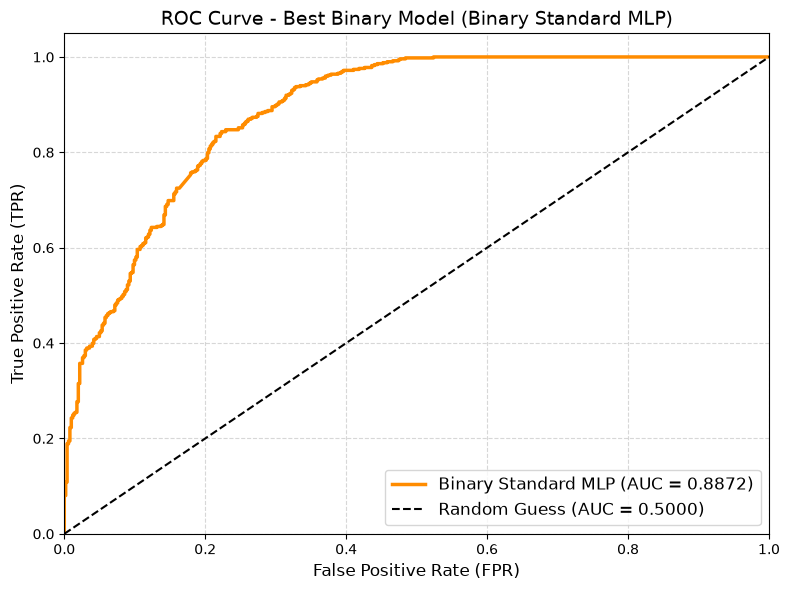

ROC-AUC Score for Binary Standard MLP: 0.8872


In [ ]:
# ============================================================
# 8. Binary ROC Curve & ROC-AUC Score
# ============================================================
from sklearn.metrics import roc_curve, auc

y_proba_best = best_model.predict_proba(X_test)
if y_proba_best.ndim > 1 and y_proba_best.shape[1] > 1:
    y_scores = y_proba_best[:, 1]
else:
    y_scores = y_proba_best

fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2.5, 
         label=f'Binary Standard MLP (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC = 0.5000)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title(f'ROC Curve - Best Binary Model ({best_model_name})', fontsize=14)
plt.legend(loc="lower right", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"ROC-AUC Score for {best_model_name}: {roc_auc:.4f}")